# Class 9: Feature Engineering & Encoding
**Machine Learning & AI BootCamp**  
*Instructor: Fahd*

---

## 🎯 What You Will Learn Today
1. **The Core Philosophy of Feature Engineering**: Why features make or break machine learning models ("Data is the fuel, features are the engine").
2. **Numerical Feature Scaling**:
   - **StandardScaler**: Z-score standardization ($\mu=0, \sigma=1$).
   - **MinMaxScaler**: Min-max normalization scaling features into $[0, 1]$.
   - **RobustScaler**: Median and Interquartile Range (IQR) scaling resistant to extreme outliers.
3. **Normalization & Power Transformations**:
   - Vector normalization (L1 and L2 norm using `Normalizer`).
   - Log transformation (`np.log1p`) for right-skewed data.
   - Power transformations (`PowerTransformer` with Yeo-Johnson and Box-Cox) to stabilize variance.
4. **Encoding Categorical Variables**:
   - **Nominal vs. Ordinal** variables: Recognizing fundamental differences.
   - **OrdinalEncoder**: Preserving meaningful order (Bronze < Silver < Gold < Platinum).
   - **One-Hot Encoding**: `pd.get_dummies` vs. `sklearn.preprocessing.OneHotEncoder` (`drop='first'`, `sparse_output=False`, handling unknown categories).
   - **LabelEncoder**: When to use (1D targets only) and why NOT to use on feature columns.
5. **Feature Creation & Domain Extraction**:
   - Interaction terms and polynomial features.
   - Domain-specific financial ratios (spending-to-income, discount utilization).
   - Unstructured text metadata extraction (character counts, word counts, sentiment keywords).
6. **Binning & Discretization**:
   - Equal-width binning (`pd.cut`).
   - Equal-frequency/quantile binning (`pd.qcut`).
   - Scikit-Learn's `KBinsDiscretizer`.
7. **Handling Date-Time Features**:
   - Timestamp parsing and component extraction (year, month, day, day of week, hour).
   - Flag engineering (`is_weekend`, elapsed time/customer tenure).
   - **Cyclical encoding**: Representing repeating periodic temporal cycles using $\sin$ and $\cos$ transformations.
8. **End-to-End Feature Engineering Workflow**: Transforming raw e-commerce customer data into a model-ready tabular feature matrix.


---
## 1. Introduction to Feature Engineering

In applied machine learning, the algorithms we use (Logistic Regression, Random Forest, XGBoost, Neural Networks) are mathematical engines that map numbers to predictions. Raw real-world data is rarely in the optimal numerical representation for these algorithms.

> **"Feature engineering is the process of using domain knowledge of the data to create features that make machine learning algorithms work."**  
> — *Jason Brownlee*

### The Feature Engineering Workflow
```
Raw Data (Strings, Timestamps, Skewed Numbers)
     ↓
Data Cleaning (Missing Values, Deduplication)
     ↓
Feature Transformation (Scaling, Normalization, Skew Correction)
     ↓
Categorical Encoding (One-Hot, Ordinal)
     ↓
Feature Creation (Ratios, Cyclical Time, Interaction Terms)
     ↓
Model-Ready Feature Matrix (X)
```


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing Tools
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    Normalizer,
    PowerTransformer,
    OrdinalEncoder,
    OneHotEncoder,
    LabelEncoder,
    KBinsDiscretizer
)

# Plotting configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

print("Feature Engineering libraries loaded successfully!")


Feature Engineering libraries loaded successfully!


### 1.1 Loading the Demonstration Dataset
We will work with `ecommerce_customer_features.csv`, an e-commerce customer dataset with diverse data types: timestamps, skewed purchase amounts, membership tiers, categories, and text comments.


In [2]:
df = pd.read_csv("ecommerce_customer_features.csv")
print("Dataset Shape:", df.shape)
print("\n--- First 5 Rows ---")
display(df.head(5))

print("\n--- Column Information & Data Types ---")
df.info()


Dataset Shape: (40, 11)

--- First 5 Rows ---


,customer_id,signup_timestamp,age,annual_income,spending_score,membership_tier,preferred_category,device_type,last_purchase_amount,discount_usage_pct,customer_feedback
0,CUST-1001,2023-01-14 09:30:00,28,52000.0,65,Bronze,Electronics,Mobile,120.5,15.0,Great gadget selection fast delivery
1,CUST-1002,2022-11-05 18:45:00,45,98000.0,82,Gold,Fashion,Desktop,450.0,5.0,Loved the winter collection quality
2,CUST-1003,2023-03-22 14:15:00,34,67000.0,45,Silver,Home,Mobile,85.2,25.0,Items arrived on time as expected
3,CUST-1004,2021-08-19 21:10:00,52,145000.0,91,Platinum,Electronics,Desktop,1250.0,0.0,Premium flagship laptop is superb
4,CUST-1005,2023-05-30 11:05:00,23,31000.0,38,Bronze,Beauty,Mobile,42.0,40.0,Affordable makeup and nice discount



--- Column Information & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           40 non-null     str    
 1   signup_timestamp      40 non-null     str    
 2   age                   40 non-null     int64  
 3   annual_income         40 non-null     float64
 4   spending_score        40 non-null     int64  
 5   membership_tier       40 non-null     str    
 6   preferred_category    40 non-null     str    
 7   device_type           40 non-null     str    
 8   last_purchase_amount  40 non-null     float64
 9   discount_usage_pct    40 non-null     float64
 10  customer_feedback     40 non-null     str    
dtypes: float64(3), int64(2), str(6)
memory usage: 3.6 KB


---
## 2. Numerical Feature Scaling

### Why do we need feature scaling?
Many machine learning algorithms compute mathematical distances or gradients:
- **Distance-based models** (KNN, K-Means, SVM, PCA): Features with large scales (e.g., Annual Income: \$100,000) will completely dominate features with small scales (e.g., Age: 25).
- **Gradient-based models** (Linear Regression, Logistic Regression, Neural Networks): Unscaled features cause elliptical contours in the loss surface, leading to erratic and slow gradient descent convergence.
- **Tree-based models** (Decision Trees, Random Forests, XGBoost): Scale-invariant because splits are based on relative rank ordering rather than absolute distances.

### The 3 Core Scalers in Scikit-Learn:

| Scaler | Mathematical Formula | Range | Outlier Sensitivity | Best Used When |
| :--- | :--- | :--- | :--- | :--- |
| **StandardScaler** | $z = \frac{x - \mu}{\sigma}$ | $(-\infty, \infty)$ (mean = 0, std = 1) | **High** (outliers distort mean $\mu$ and std $\sigma$) | Data is approximately Gaussian / Normal; standard default. |
| **MinMaxScaler** | $x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$ | $[0, 1]$ (or custom $[a, b]$) | **Very High** (outliers compress normal values into narrow range) | Neural Networks, Image processing, bounded outputs required. |
| **RobustScaler** | $x_{robust} = \frac{x - Q_2}{IQR} = \frac{x - \text{median}}{Q_3 - Q_1}$ | $(-\infty, \infty)$ | **Very Low** (uses median & IQR, ignores extreme tails) | Data contains extreme outliers that cannot be removed. |


In [3]:
# Select numerical features for demonstration
num_cols = ["age", "annual_income", "last_purchase_amount"]
df_num = df[num_cols].copy()

# Initialize scalers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
robust_scaler = RobustScaler()

# Fit and transform
df_standard = pd.DataFrame(standard_scaler.fit_transform(df_num), columns=[f"{c}_std" for c in num_cols])
df_minmax = pd.DataFrame(minmax_scaler.fit_transform(df_num), columns=[f"{c}_minmax" for c in num_cols])
df_robust = pd.DataFrame(robust_scaler.fit_transform(df_num), columns=[f"{c}_robust" for c in num_cols])

# Combine for comparison
comparison_df = pd.concat([
    df_num[["last_purchase_amount"]].rename(columns={"last_purchase_amount": "Original ($)"}),
    df_standard[["last_purchase_amount_std"]].rename(columns={"last_purchase_amount_std": "StandardScaler"}),
    df_minmax[["last_purchase_amount_minmax"]].rename(columns={"last_purchase_amount_minmax": "MinMaxScaler"}),
    df_robust[["last_purchase_amount_robust"]].rename(columns={"last_purchase_amount_robust": "RobustScaler"})
], axis=1)

print("--- Comparison of Scalers on 'last_purchase_amount' (First 5 Rows) ---")
display(comparison_df.head(5))


--- Comparison of Scalers on 'last_purchase_amount' (First 5 Rows) ---


,Original ($),StandardScaler,MinMaxScaler,RobustScaler
0,120.5,-0.610725,0.032671,-0.140034
1,450.0,-0.143859,0.151625,0.420102
2,85.2,-0.660741,0.019928,-0.200042
3,1250.0,0.989655,0.440433,1.780068
4,42.0,-0.721951,0.004332,-0.273481


### 2.1 Visualizing the Impact of Scaling on Distributions
Notice that all three scalers **preserve the original relative shape** of the distribution, but shift the location and scale the spread differently.


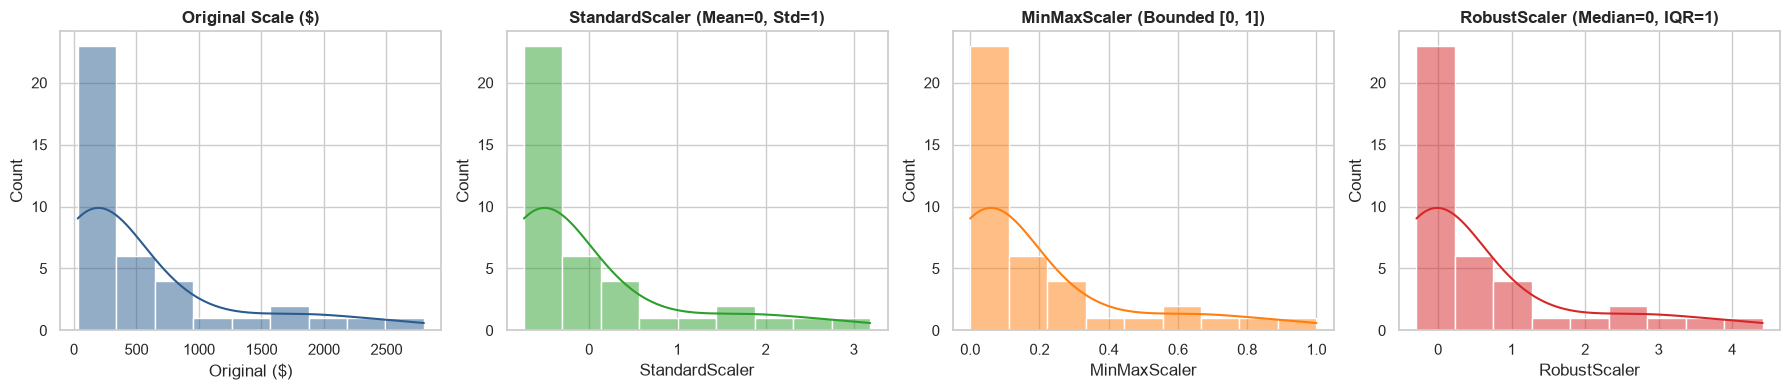

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

sns.histplot(comparison_df["Original ($)"], kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Original Scale ($)", fontweight="bold")

sns.histplot(comparison_df["StandardScaler"], kde=True, ax=axes[1], color="#2ca02c")
axes[1].set_title("StandardScaler (Mean=0, Std=1)", fontweight="bold")

sns.histplot(comparison_df["MinMaxScaler"], kde=True, ax=axes[2], color="#ff7f0e")
axes[2].set_title("MinMaxScaler (Bounded [0, 1])", fontweight="bold")

sns.histplot(comparison_df["RobustScaler"], kde=True, ax=axes[3], color="#d62728")
axes[3].set_title("RobustScaler (Median=0, IQR=1)", fontweight="bold")

plt.tight_layout()
plt.show()


---
## 3. Normalization Techniques & Power Transformations

### 3.1 Scaling vs. Normalization: What's the Difference?
- **Feature Scaling (Column-wise)**: Operates independently down each column (feature), transforming features to have similar ranges.
- **Normalization (Row-wise / Sample-wise)**: Operates across each row (sample), scaling the sample vector to have unit length ($L_1$ norm or $L_2$ norm).
  - Common in text classification (TF-IDF vectors), clustering, and calculating Cosine Similarity:
    $$\|x\|_2 = \sqrt{\sum x_i^2} = 1$$

### 3.2 Transforming Skewed Features (Power Transforms)
Many linear and parametric algorithms assume features are approximately normally distributed.
- **Log Transformation (`np.log1p`)**: Computes $\ln(1 + x)$. Perfect for right-skewed data with positive values and zeros. Inverted with `np.expm1`.
- **Yeo-Johnson Transformation (`PowerTransformer`)**: Stabilizes variance and minimizes skewness across positive, zero, and negative values.
- **Box-Cox Transformation**: Requires strictly positive values ($x > 0$).


In [5]:
# 1. Vector Normalization across numerical attributes
normalizer = Normalizer(norm="l2")
df_normalized = pd.DataFrame(normalizer.fit_transform(df_num), columns=num_cols)
print("Sample row after L2 normalization (sum of squares = 1):")
print(df_normalized.iloc[0])
print(f"Norm check (sqrt of sum of squares): {np.sqrt((df_normalized.iloc[0]**2).sum()):.4f}")

# 2. Skewness correction on 'last_purchase_amount'
original_skew = df["last_purchase_amount"].skew()

# Method A: Log1p transform
df["log_purchase_amount"] = np.log1p(df["last_purchase_amount"])
log_skew = df["log_purchase_amount"].skew()

# Method B: Yeo-Johnson PowerTransformer
pt = PowerTransformer(method="yeo-johnson")
df["yeojohnson_purchase_amount"] = pt.fit_transform(df[["last_purchase_amount"]])
pt_skew = df["yeojohnson_purchase_amount"].skew()

print(f"\n--- Skewness Comparison for 'last_purchase_amount' ---")
print(f"Original Skewness:      {original_skew:.3f}")
print(f"Log1p Skewness:         {log_skew:.3f}")
print(f"Yeo-Johnson Skewness:   {pt_skew:.3f}")


Sample row after L2 normalization (sum of squares = 1):
age                     0.000538
annual_income           0.999997
last_purchase_amount    0.002317
Name: 0, dtype: float64
Norm check (sqrt of sum of squares): 1.0000

--- Skewness Comparison for 'last_purchase_amount' ---
Original Skewness:      1.797
Log1p Skewness:         0.298
Yeo-Johnson Skewness:   0.061


---
## 4. Encoding Categorical Variables

Categorical variables represent discrete qualitative groups. Algorithms cannot directly calculate matrix products on text strings, so we must encode them into numerical formats.

### 4.1 Nominal vs. Ordinal Variables
- **Ordinal Variables**: Have an inherent order or natural rank (e.g., Education: High School < Bachelor < Master < PhD; Membership: Bronze < Silver < Gold < Platinum).
  - **Treatment**: `OrdinalEncoder` mapping to ordered integers ($0, 1, 2, 3$).
- **Nominal Variables**: Have NO inherent order or hierarchy (e.g., `preferred_category`: Electronics, Fashion, Home; `device_type`: Desktop, Mobile, Tablet).
  - **Treatment**: One-Hot Encoding (OHE) creating binary indicator columns ($0$ or $1$).

### 4.2 The Dummy Variable Trap (Multicollinearity)
When one-hot encoding a feature with $K$ categories, the sum of all $K$ binary columns is always 1. This creates perfect multicollinearity for linear models.
To prevent this, drop the first category (`drop='first'`), resulting in $K - 1$ columns.


In [6]:
# 1. Ordinal Encoding on membership_tier
tier_order = [["Bronze", "Silver", "Gold", "Platinum"]]
ordinal_enc = OrdinalEncoder(categories=tier_order)

df["membership_tier_encoded"] = ordinal_enc.fit_transform(df[["membership_tier"]])

print("--- Ordinal Encoding Mapping for 'membership_tier' ---")
display(df[["membership_tier", "membership_tier_encoded"]].drop_duplicates().sort_values("membership_tier_encoded"))

# 2. One-Hot Encoding using pd.get_dummies (for quick EDA)
ohe_dummies = pd.get_dummies(df["device_type"], prefix="device", drop_first=True, dtype=int)
print("\n--- One-Hot Encoding with pd.get_dummies(drop_first=True) ---")
display(ohe_dummies.head(4))

# 3. Production One-Hot Encoding using Scikit-Learn
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
cat_cols = ["preferred_category", "device_type"]
ohe_encoded = ohe.fit_transform(df[cat_cols])
ohe_feature_names = ohe.get_feature_names_out(cat_cols)

df_ohe = pd.DataFrame(ohe_encoded, columns=ohe_feature_names)
print(f"\n--- Scikit-Learn OneHotEncoder Created {len(ohe_feature_names)} Binary Columns ---")
display(df_ohe.head(4))


--- Ordinal Encoding Mapping for 'membership_tier' ---


,membership_tier,membership_tier_encoded
0,Bronze,0.0
2,Silver,1.0
1,Gold,2.0
3,Platinum,3.0



--- One-Hot Encoding with pd.get_dummies(drop_first=True) ---


,device_Mobile,device_Tablet
0,1,0
1,0,0
2,1,0
3,0,0



--- Scikit-Learn OneHotEncoder Created 6 Binary Columns ---


,preferred_category_Electronics,preferred_category_Fashion,preferred_category_Home,preferred_category_Sports,device_type_Mobile,device_type_Tablet
0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0


### 4.3 Why NOT use LabelEncoder for Features?
`LabelEncoder` is designed strictly for **1D target labels ($y$)**, not 2D feature matrices ($X$).
If applied to a nominal feature like `preferred_category`, it assigns arbitrary integers ($0, 1, 2, 3$). A linear or distance model will interpret this as `Electronics (0) < Fashion (1) < Home (2)`, creating false artificial order!


---
## 5. Feature Creation & Domain Extraction

Domain feature engineering transforms domain expertise into mathematical signals:
1. **Mathematical Ratios**: Comparing expenditures against earnings or baseline averages.
2. **Interaction Terms**: Multiplying features together to model non-linear synergies ($X_1 \times X_2$).
3. **Text-Derived Metadata**: Extracting quantitative attributes from unstructured notes or customer reviews.


In [7]:
# 1. Spending-to-Income Ratio (Monthly)
# Monthly income = annual_income / 12
df["spending_to_income_ratio"] = df["last_purchase_amount"] / (df["annual_income"] / 12.0)

# 2. Effective Discount Savings ($)
df["discount_savings_amount"] = df["last_purchase_amount"] * (df["discount_usage_pct"] / 100.0)

# 3. Interaction Feature: Income × Spending Score
df["income_x_spending_score"] = (df["annual_income"] / 1000.0) * df["spending_score"]

# 4. Text Feature Extraction from 'customer_feedback'
df["feedback_char_count"] = df["customer_feedback"].str.len()
df["feedback_word_count"] = df["customer_feedback"].str.split().str.len()

# Extract positive keyword presence (Flag: 1 if positive word present, 0 otherwise)
positive_keywords = r"superb|great|excellent|loved|perfect|nice"
df["has_positive_sentiment"] = df["customer_feedback"].str.contains(positive_keywords, case=False).astype(int)

print("--- Newly Created Domain Features (First 5 Rows) ---")
display(df[[
    "spending_to_income_ratio",
    "discount_savings_amount",
    "income_x_spending_score",
    "feedback_word_count",
    "has_positive_sentiment"
]].head(5))


--- Newly Created Domain Features (First 5 Rows) ---


,spending_to_income_ratio,discount_savings_amount,income_x_spending_score,feedback_word_count,has_positive_sentiment
0,0.027808,18.075,3380.0,5,1
1,0.055102,22.500,8036.0,5,1
2,0.015260,21.300,3015.0,6,0
3,0.103448,0.000,13195.0,5,1
4,0.016258,16.800,1178.0,5,1


---
## 6. Binning and Discretization

Discretization converts continuous numerical variables into discrete intervals/bins.
- **Why bin?** Reduces noise, prevents overfitting in small samples, captures non-linear relationships, and creates human-interpretable categories.
- **Equal-Width Binning (`pd.cut`)**: Divides data range into bins of equal numerical length.
- **Equal-Frequency Binning (`pd.qcut`)**: Divides data such that each bin has roughly the same number of samples (quantiles).
- **Scikit-Learn `KBinsDiscretizer`**: Production transformer with strategies `'uniform'`, `'quantile'`, or `'kmeans'`.


In [8]:
# 1. Equal-Width Binning with pd.cut
age_bins = [18, 30, 45, 70]
age_labels = ["Young Adult (18-30)", "Middle Age (31-45)", "Senior (46+)"]
df["age_group_equal_width"] = pd.cut(df["age"], bins=age_bins, labels=age_labels)

# 2. Equal-Frequency Binning with pd.qcut (4 quartiles: Low, Medium, High, Ultra)
income_labels = ["Q1_Low", "Q2_Medium", "Q3_High", "Q4_Ultra"]
df["income_tier_equal_freq"] = pd.qcut(df["annual_income"], q=4, labels=income_labels)

# 3. Scikit-Learn KBinsDiscretizer
kbd = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile")
df["spending_score_bin"] = kbd.fit_transform(df[["spending_score"]])

print("--- Age Bin Counts (Equal-Width) ---")
print(df["age_group_equal_width"].value_counts())

print("\n--- Income Bin Counts (Equal-Frequency / Quantiles) ---")
print(df["income_tier_equal_freq"].value_counts())

print("\n--- Binning Results Sample ---")
display(df[["age", "age_group_equal_width", "annual_income", "income_tier_equal_freq", "spending_score_bin"]].head(5))


--- Age Bin Counts (Equal-Width) ---
age_group_equal_width
Young Adult (18-30)    14
Middle Age (31-45)     14
Senior (46+)           12
Name: count, dtype: int64

--- Income Bin Counts (Equal-Frequency / Quantiles) ---
income_tier_equal_freq
Q1_Low       10
Q2_Medium    10
Q3_High      10
Q4_Ultra     10
Name: count, dtype: int64

--- Binning Results Sample ---


,age,age_group_equal_width,annual_income,income_tier_equal_freq,spending_score_bin
0,28,Young Adult (18-30),52000.0,Q1_Low,1.0
1,45,Middle Age (31-45),98000.0,Q3_High,2.0
2,34,Middle Age (31-45),67000.0,Q2_Medium,0.0
3,52,Senior (46+),145000.0,Q4_Ultra,2.0
4,23,Young Adult (18-30),31000.0,Q1_Low,0.0


---
## 7. Handling Date-Time Features

Raw timestamp strings cannot be parsed directly by machine learning estimators. We must decompose them into structured temporal signals.

### 7.1 Temporal Signal Extraction:
- **Components**: Year, Month, Day, Day of Week ($0=\text{Monday}, 6=\text{Sunday}$), Hour.
- **Binary indicators**: `is_weekend` ($1$ if Saturday or Sunday, $0$ otherwise).
- **Elapsed Time / Tenure**: Days elapsed between signup and a reference date.

### 7.2 Cyclical Feature Encoding (Sine & Cosine)
Consider the hour of the day: Hour 23 (11:00 PM) and Hour 0 (12:00 AM) are adjacent in reality (only 1 hour apart), but numerically $|23 - 0| = 23$!
To teach a machine learning model that time is continuous and repeating, we map periodic values onto a 2D circle using trigonometric functions:
$$x_{\sin} = \sin\left(\frac{2\pi \cdot t}{T}\right), \quad x_{\cos} = \cos\left(\frac{2\pi \cdot t}{T}\right)$$
where $T=24$ for hours of the day, or $T=12$ for months of the year.


In [9]:
# 1. Parse string to datetime
df["signup_timestamp"] = pd.to_datetime(df["signup_timestamp"])

# 2. Extract components
df["signup_year"] = df["signup_timestamp"].dt.year
df["signup_month"] = df["signup_timestamp"].dt.month
df["signup_day"] = df["signup_timestamp"].dt.day
df["signup_dayofweek"] = df["signup_timestamp"].dt.dayofweek
df["signup_hour"] = df["signup_timestamp"].dt.hour

# 3. Binary Weekend Flag (5 = Saturday, 6 = Sunday)
df["is_weekend"] = df["signup_dayofweek"].isin([5, 6]).astype(int)

# 4. Account Tenure in Days (Relative to 2024-01-01)
reference_date = pd.to_datetime("2024-01-01")
df["tenure_days"] = (reference_date - df["signup_timestamp"]).dt.days

# 5. Cyclical Encoding for Hour (Period T = 24)
df["hour_sin"] = np.sin(2 * np.pi * df["signup_hour"] / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df["signup_hour"] / 24.0)

print("--- Extracted Date-Time & Cyclical Features ---")
display(df[[
    "signup_timestamp", "signup_month", "signup_hour", 
    "is_weekend", "tenure_days", "hour_sin", "hour_cos"
]].head(5))


--- Extracted Date-Time & Cyclical Features ---


,signup_timestamp,signup_month,signup_hour,is_weekend,tenure_days,hour_sin,hour_cos
0,2023-01-14 09:30:00,1,9,1,351,0.707107,-7.071068e-01
1,2022-11-05 18:45:00,11,18,1,421,-1.000000,-1.836970e-16
2,2023-03-22 14:15:00,3,14,0,284,-0.500000,-8.660254e-01
3,2021-08-19 21:10:00,8,21,0,864,-0.707107,7.071068e-01
4,2023-05-30 11:05:00,5,11,0,215,0.258819,-9.659258e-01


### 7.3 Visualizing the 24-Hour Cyclical Clock
Notice how mapping with $\sin$ and $\cos$ perfectly plots the hours on a 24-hour circular clock, ensuring hour 23 and hour 0 are immediate neighbors.


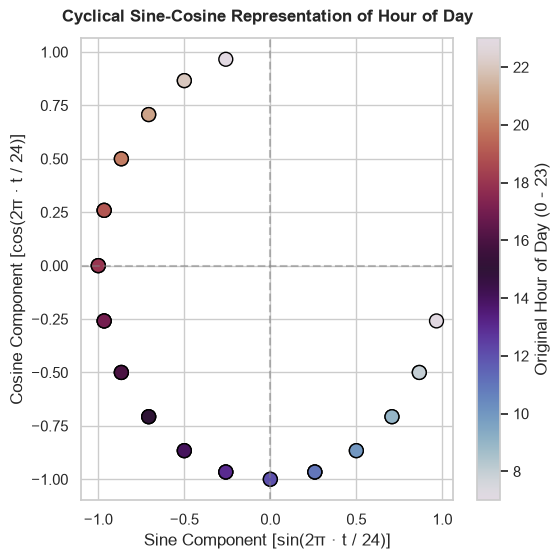

In [10]:
plt.figure(figsize=(6, 6))
scatter = plt.scatter(df["hour_sin"], df["hour_cos"], c=df["signup_hour"], cmap="twilight", s=100, edgecolors="black")
plt.colorbar(scatter, label="Original Hour of Day (0 - 23)")
plt.title("Cyclical Sine-Cosine Representation of Hour of Day", fontweight="bold", pad=12)
plt.xlabel("Sine Component [sin(2π · t / 24)]")
plt.ylabel("Cosine Component [cos(2π · t / 24)]")
plt.axhline(0, color="grey", linestyle="--", alpha=0.5)
plt.axvline(0, color="grey", linestyle="--", alpha=0.5)
plt.grid(True)
plt.show()


---
## 📝 Summary & Key Takeaways

1. **Feature Scaling**:
   - Use **StandardScaler** for algorithms assuming zero-mean normal distributions (Ridge/Lasso, Logistic Regression, SVM).
   - Use **MinMaxScaler** when values must be strictly bounded in $[0, 1]$ (e.g. Neural Networks).
   - Use **RobustScaler** whenever severe outliers exist and cannot be removed.
2. **Transformations**:
   - Use `np.log1p` or `PowerTransformer` (Yeo-Johnson) to stabilize variance and convert right-skewed distributions into bell curves.
3. **Categorical Encoding**:
   - Use **OrdinalEncoder** with custom ordered lists for ordinal hierarchies (Bronze < Silver < Gold).
   - Use **OneHotEncoder** with `drop='first'` for nominal features to eliminate multicollinearity.
   - Never use `LabelEncoder` on feature columns.
4. **Feature Creation**:
   - Combine features using ratios, interactions, and text-derived lengths to inject domain expertise.
5. **Date-Time Engineering**:
   - Extract calendar components, tenure/recency, and always use **cyclical sine/cosine encoding** for periodic variables like hours, days of week, and months.

**Next Class**: **Class 10: Train-Test Split & Data Leakage Prevention** (Stratified sampling, cross-validation, SMOTE, and scikit-learn pipelines)!
